线性回归，通常用于连续值预测回归

广告投入比与销售额预测

In [14]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score)
import joblib

In [4]:
# 1. 加载数据集
# 读取 Advertising.csv，检查行数、列名、数据类型

# 所有特征：
#    - TV：电视广告投入。
#    - Radio：广播广告投入。
#    - Newspaper：报纸广告投入。
#    - Sales：销售额。

data = pd.read_csv("../../../data/ml/advertising.csv")
print(data.head())
data.drop("Unnamed: 0", inplace=True, axis=1)
print(data.head())



   Unnamed: 0     TV  Radio  Newspaper  Sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9


In [28]:
# 2. 数据探索与清洗
# 检查缺失值、重复值、异常值、数据分布
#阶段 2：数据探索与清洗
# 目标： 确保输入模型的数据质量满足要求。
# 1. 统计每一列的缺失值数量。
# 2. 检查重复行。
# 3. 使用描述性统计查看均值、标准差、最小值、最大值和分位数。
# 4. 检查广告投入和销售额是否存在明显异常值。
# 5. 查看各特征与 Sales 的相关性。
# 6. 根据检查结果决定是否需要清洗。
# 注意：
# - 不要仅仅因为存在极端值就直接删除，先判断它是否合理。
# - 如果存在缺失值，应在划分数据集后，使用仅基于训练集拟合的填补方法，避免数据泄漏。
# - 经典数据集通常比较干净，但仍应实际检查。

# 每列缺失值数量
print(data.isnull().sum())

# 每列缺失值比例
print(data.isnull().mean() * 100)

# 缺失值总数
print("缺失值总数：", data.isnull().sum().sum())

numeric_df = data.select_dtypes(include="number")
print("各列无穷值数量：", np.isinf(numeric_df).sum())

# 重复行数量
print("重复行数量：", data.duplicated().sum())

# 查看重复行
print(data[data.duplicated(keep=False)])

# 查看均值、标准差、最小值、四分位数、最大值
print(data.describe())



TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
TV           0.0
Radio        0.0
Newspaper    0.0
Sales        0.0
dtype: float64
缺失值总数： 0
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object
各列无穷值数量：
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64
重复行数量： 0
Empty DataFrame
Columns: [TV, Radio, Newspaper, Sales]
Index: []


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

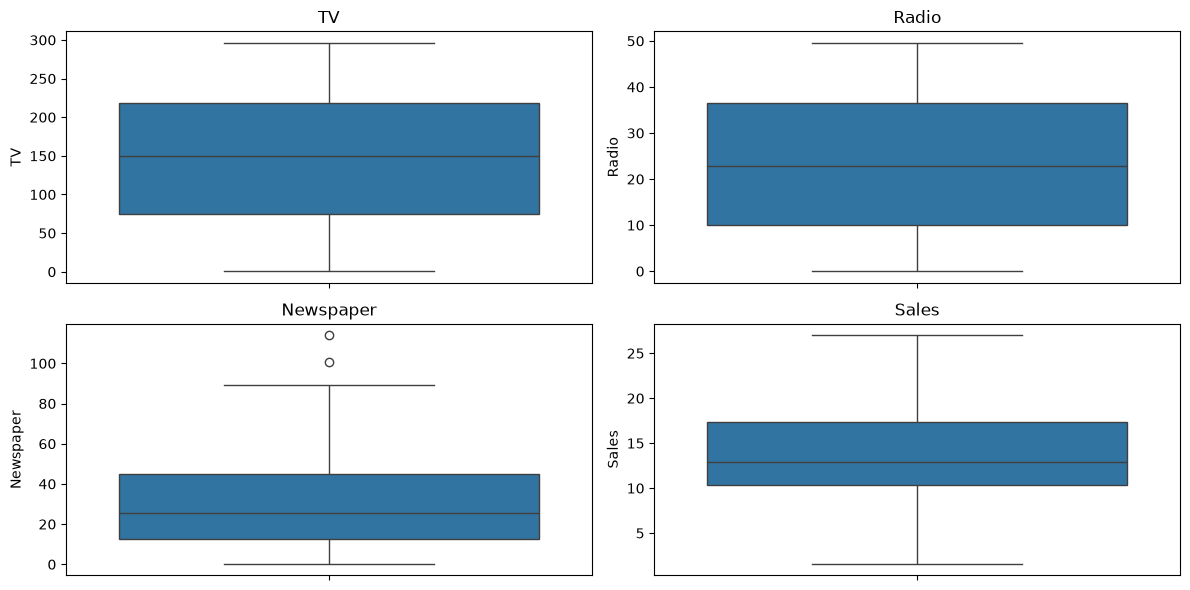

In [31]:
# 五、检查异常值 方法一：使用箱线图
columns = ["TV", "Radio", "Newspaper", "Sales"]

plt.figure(figsize=(12, 6))

for i, col in enumerate(columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=data[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [32]:
# 五、检查异常值 方法二：使用 IQR（四分位距）识别候选异常值

columns = ["TV", "Radio", "Newspaper", "Sales"]

for col in columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = data[(data[col] < lower) | (data[col] > upper)]

    print(f"\n{col}")
    print("下界：", lower)
    print("上界：", upper)
    print("候选异常值数量：", len(outliers))
    print(outliers[[col]])


TV
下界： -142.29999999999998
上界： 435.5
候选异常值数量： 0
Empty DataFrame
Columns: [TV]
Index: []

Radio
下界： -29.849999999999994
上界： 76.35
候选异常值数量： 0
Empty DataFrame
Columns: [Radio]
Index: []

Newspaper
下界： -35.775000000000006
上界： 93.625
候选异常值数量： 2
     Newspaper
16       114.0
101      100.9

Sales
下界： -0.16249999999999787
上界： 27.937499999999996
候选异常值数量： 0
Empty DataFrame
Columns: [Sales]
Index: []


                 TV     Radio  Newspaper     Sales
TV         1.000000  0.054809   0.056648  0.782224
Radio      0.054809  1.000000   0.354104  0.576223
Newspaper  0.056648  0.354104   1.000000  0.228299
Sales      0.782224  0.576223   0.228299  1.000000


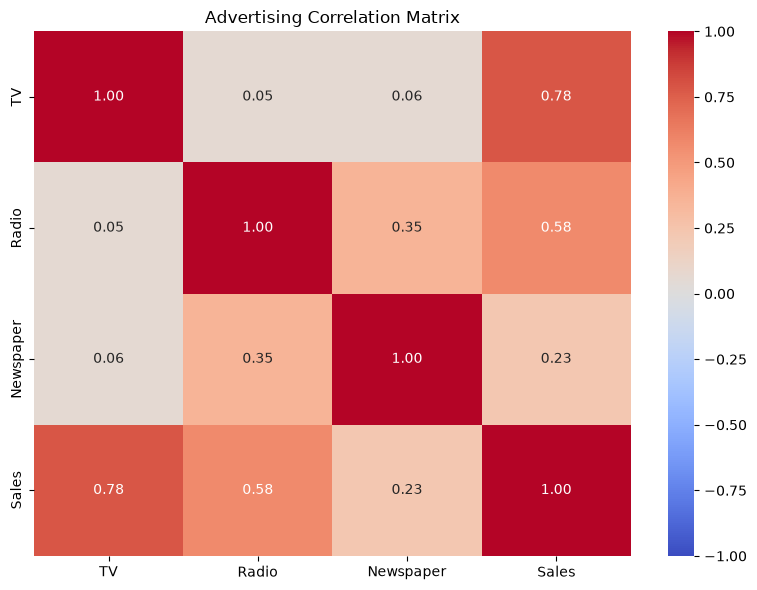

In [35]:
# 六、分析特征与 Sales 的相关性
corr = data[["TV", "Radio", "Newspaper", "Sales"]].corr()
print(corr)

# 2. 使用热力图可视化
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Advertising Correlation Matrix")
plt.tight_layout()
plt.show()

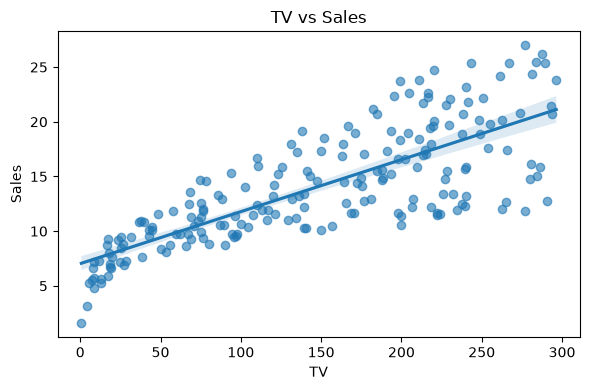

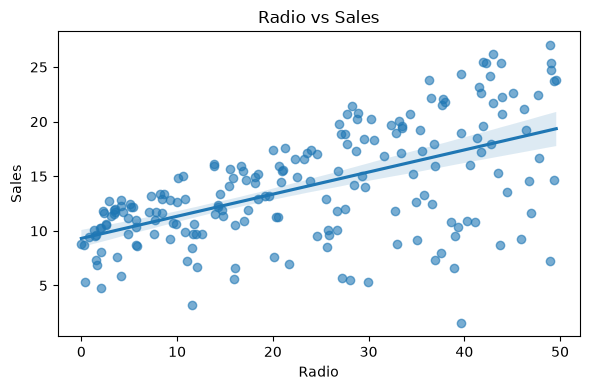

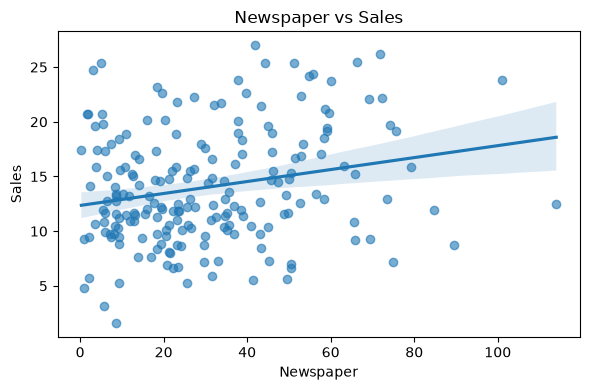

In [36]:
# 3. 单独分析各广告渠道与销售额的关系

features = ["TV", "Radio", "Newspaper"]

for col in features:
    plt.figure(figsize=(6, 4))

    sns.regplot(
        data=data,
        x=col,
        y="Sales",
        scatter_kws={"alpha": 0.6}
    )

    plt.title(f"{col} vs Sales")
    plt.tight_layout()
    plt.show()

In [38]:
# 七、根据检查结果决定是否清洗
print("数据形状：", data.shape)

print("\n缺失值：")
print(data.isnull().sum())

print("\n重复行数量：", data.duplicated().sum())

print("\n负数数量：")
print((data[["TV", "Radio", "Newspaper", "Sales"]] < 0).sum())

print("\n描述性统计：")
print(data[["TV", "Radio", "Newspaper", "Sales"]].describe())

数据形状： (200, 4)

缺失值：
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

重复行数量： 0

负数数量：
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

描述性统计：
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  114.000000   27.000000


In [7]:
# 3. 定义特征 X 和目标 y
# X = TV、Radio、Newspaper；y = Sales
X = data.drop(["Sales"], axis=1)
y = data["Sales"]
print(data.head(), X.head(), y.head())


      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9       TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4 0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64


In [8]:
# 4. 划分训练集、验证集、测试集
# 训练集 80%，验证集 10%，测试集 10%
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, random_state=23)
X_validation, X_test, y_validation, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=23)
print(len(X), len(X_train), len(X_validation), len(X_test))

200 160 20 20


In [9]:
# 5. 建立并训练线性回归模型
# 使用 sklearn.linear_model.LinearRegression
model = LinearRegression(fit_intercept=True)
model.fit(X_train, y_train)
print("coef_: ", model.coef_)
print("intercept_: ", model.intercept_)

coef_:  [4.64851464e-02 1.81416165e-01 7.90438566e-05]
intercept_:  2.928132811422506


In [10]:
# 6. 验证与模型评估
# 计算 MAE、MSE、RMSE、R²，分析预测误差
mae = mean_absolute_error(y_validation, model.predict(X_validation))
mse = mean_squared_error(y_validation, model.predict(X_validation))
rmse = root_mean_squared_error(y_validation, model.predict(X_validation))
r2 = r2_score(y_validation, model.predict(X_validation))
print("mae: ", mae)
print("mse: ", mse)
print("rmse: ", rmse)
print("r2: ", r2)


mae:  1.4927295721567044
mse:  3.1122411722075256
rmse:  1.764154520501967
r2:  0.8787476690945437


In [25]:
# 7. 测试最终模型
# 使用测试集进行最终评估
test_mae = mean_absolute_error(y_test, model.predict(X_test))
test_mse = mean_squared_error(y_test, model.predict(X_test))
test_rmse = root_mean_squared_error(y_test, model.predict(X_test))
test_r2 = r2_score(y_test, model.predict(X_test))
print("test_mae: ", test_mae)
print("test_mse: ", test_mse)
print("test_rmse: ", test_rmse)
print("test_r2: ", test_r2)

pred = model.predict(X_test)
res = np.column_stack((y_test,pred, y_test - pred))
res

test_mae:  1.3099363958921266
test_mse:  2.5266183294043056
test_rmse:  1.5895339975616456
test_r2:  0.9319189173983464


array([[19.4       , 19.13005428,  0.26994572],
       [ 9.4       ,  6.62590078,  2.77409922],
       [25.5       , 23.73603195,  1.76396805],
       [18.        , 17.20515403,  0.79484597],
       [ 8.7       ,  7.18664871,  1.51335129],
       [12.2       , 13.48615859, -1.28615859],
       [22.6       , 20.6410061 ,  1.9589939 ],
       [14.2       , 13.70107607,  0.49892393],
       [ 9.9       ,  8.3975302 ,  1.5024698 ],
       [12.7       , 15.7854994 , -3.0854994 ],
       [10.7       ,  9.33712125,  1.36287875],
       [27.        , 24.67442433,  2.32557567],
       [ 4.8       ,  3.70895806,  1.09104194],
       [19.        , 18.38797902,  0.61202098],
       [14.6       , 14.11275095,  0.48724905],
       [ 5.7       ,  8.25329371, -2.55329371],
       [21.4       , 21.68112434, -0.28112434],
       [13.4       , 15.27820199, -1.87820199],
       [14.5       , 14.37028391,  0.12971609],
       [10.1       , 10.12936952, -0.02936952]])

In [16]:
# 8. 保存模型并预测新数据
# 保存训练好的模型，输入新的广告投入，预测销售额
# advertising_linear_model.joblib

joblib.dump(model, '../../../data/output/advertising_linear_model.pkl')


['../../../data/output/advertising_linear_model.pkl']

In [24]:
# 9：预测新的广告投入
# 目标： 输入一组新的广告预算，预测对应销售额。
load_model = joblib.load(open('../../../data/output/advertising_linear_model.pkl', 'rb'))
# new_X = np.array([[200, 35, 40]], dtype=float)
new_X = pd.DataFrame({
    "TV": [200, 100],
    "Radio": [35, 20],
    "Newspaper": [40, 10],
})
print(new_X)
new_pred = load_model.predict(new_X)
new_pred

    TV  Radio  Newspaper
0  200     35         40
1  100     20         10


array([18.57788961, 11.20576118])